In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_excel("Lake_Ecosystem_Conservation_Dataset_10000_Rows.xlsx")

df["Sample_Date"] = pd.to_datetime(df["Sample_Date"])
df["Month"] = df["Sample_Date"].dt.to_period("M")

sns.set_theme(style="whitegrid")

print("Dataset loaded:", len(df), "records")

Dataset loaded: 10000 records


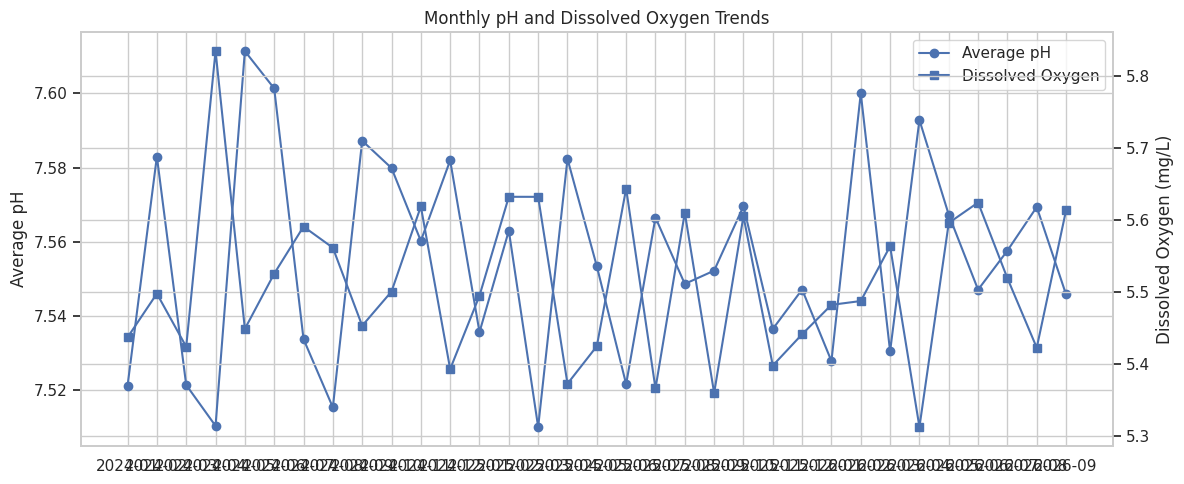

In [ ]:
monthly = df.groupby("Month").agg({
    "pH_Level": "mean",
    "Dissolved_Oxygen_mg_L": "mean"
}).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))

x = monthly["Month"].astype(str)

ax1.plot(x, monthly["pH_Level"],
         marker="o", label="Average pH")

ax1.set_ylabel("Average pH")

ax2 = ax1.twinx()

ax2.plot(x, monthly["Dissolved_Oxygen_mg_L"],
         marker="s", label="Dissolved Oxygen")

ax2.set_ylabel("Dissolved Oxygen (mg/L)")

ax1.set_title("Monthly pH and Dissolved Oxygen Trends")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(lines1 + lines2, labels1 + labels2)

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("Graph1.png", dpi=300)
plt.show()

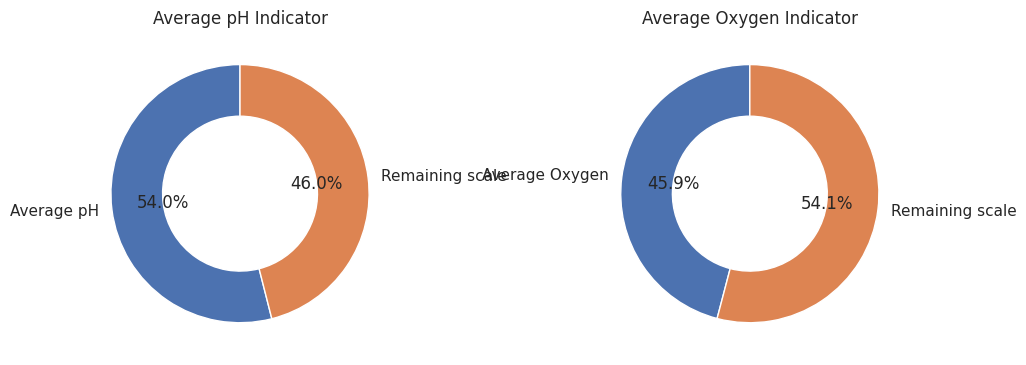

In [ ]:
avg_ph = df["pH_Level"].mean()
avg_oxygen = df["Dissolved_Oxygen_mg_L"].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].pie(
    [avg_ph, 14 - avg_ph],
    labels=["Average pH", "Remaining scale"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.4)
)

axes[0].set_title("Average pH Indicator")

axes[1].pie(
    [avg_oxygen, 12 - avg_oxygen],
    labels=["Average Oxygen", "Remaining scale"],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops=dict(width=0.4)
)

axes[1].set_title("Average Oxygen Indicator")

plt.tight_layout()
plt.savefig("Graph2.png", dpi=300)
plt.show()

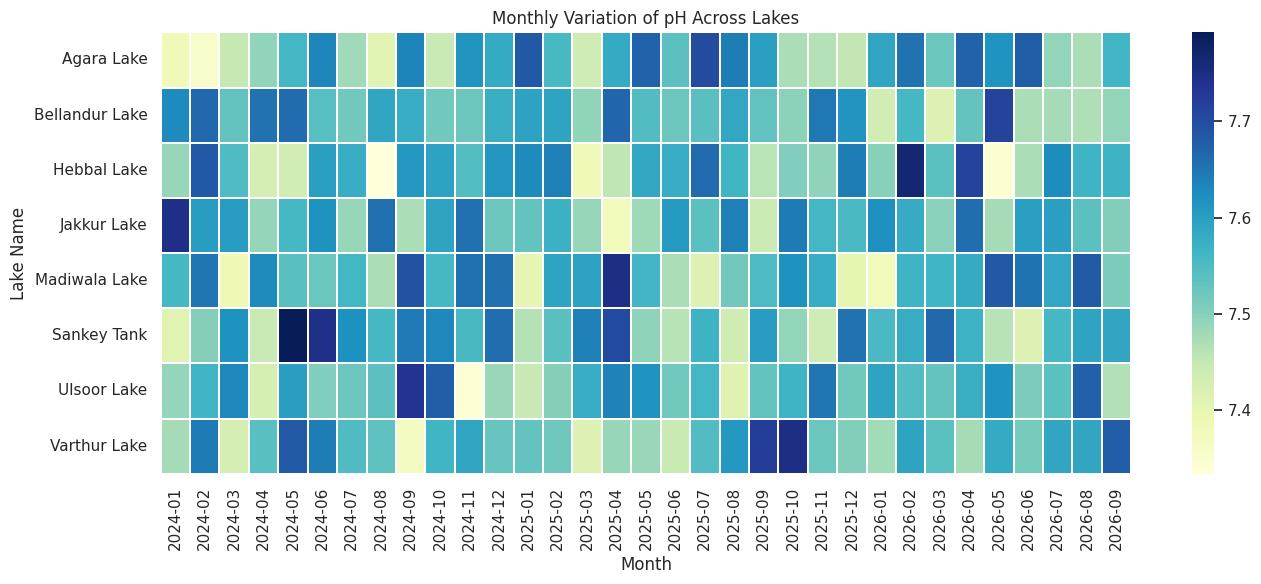

In [ ]:
df["Month_Name"] = df["Sample_Date"].dt.strftime("%Y-%m")

heatmap_data = df.pivot_table(
    index="Lake_Name",
    columns="Month_Name",
    values="pH_Level",
    aggfunc="mean"
)

plt.figure(figsize=(14, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    linewidths=0.3
)

plt.title("Monthly Variation of pH Across Lakes")
plt.xlabel("Month")
plt.ylabel("Lake Name")

plt.tight_layout()
plt.savefig("Graph3.png", dpi=300)
plt.show()

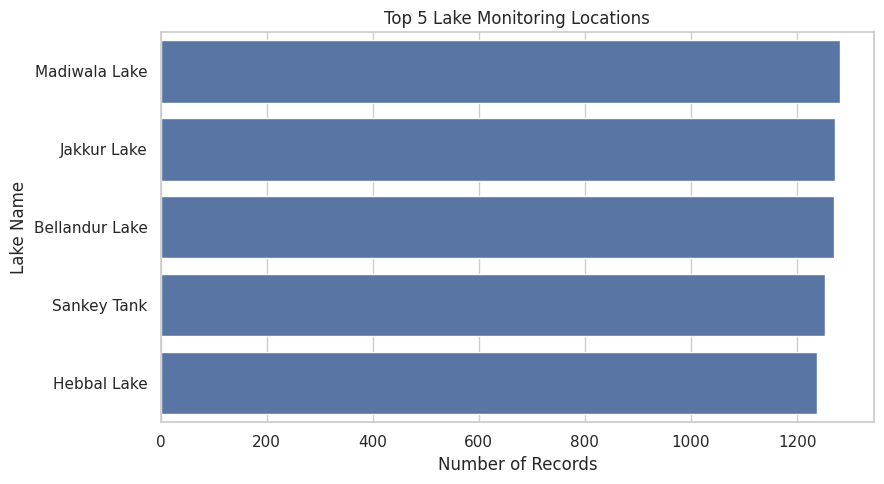

In [ ]:
top_lakes = df["Lake_Name"].value_counts().head(5)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=top_lakes.values,
    y=top_lakes.index
)

plt.title("Top 5 Lake Monitoring Locations")
plt.xlabel("Number of Records")
plt.ylabel("Lake Name")

plt.tight_layout()
plt.savefig("Graph4.png", dpi=300)
plt.show()